# Technical Milestone Report - Code

This notebook contains complementary code for the Technical Milestone Report on homeostatic plasticity in the olfactory bulb.

**Structure:**
1. Circuit Mathematics - Naka-Rushton function and signal flow
2. Fixed Point Iteration - Solving for steady-state neuron firing rates
3. Parameter Initialisation - Finding biologically realistic parameters
4. Stability - Analysis of network stability around fixed points
5. Parameter Changes Preserving Output - Hessian analysis and participation ratio


In [87]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from jaxopt import AndersonAcceleration
import pickle
import os
import optax


# set random seed for reproducibility
key = jax.random.PRNGKey(42)
np.random.seed(42)

# plotting style
plt.rcParams.update({'font.size': 12, 'figure.figsize': (10, 6)})


In [88]:

# find mitral output using solved g
# currently without granule cell
def mitral_output(theta, x, m):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)

    g = solve_fixed_point(theta, x, m)
    b = nr(w_osn_b * alpha * x)
    r = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g)

    base_y = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g + w_r_y * r)

    return r, g, b, base_y  # Return base_y as y (granule cell computation is commented out)


# solve fixed point via Anderson - return g
# Use the local mitral_fixed_point function
def solve_fixed_point(theta, x, m):
    # Unpack all parameters needed for mitral_fixed_point
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)

    # Local mitral_fixed_point signature: (g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha)
    g0 = jnp.zeros(m)
    aa = AndersonAcceleration(mitral_fixed_point, history_size=5, tol=1e-10, maxiter=50)
    solution = aa.run(g0, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha)
    g_fixed = solution.params
    return g_fixed

# fixed-point function
def mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha):
    """
    Fixed point equation for green neurons
    """
    b_input = w_osn_b * alpha * x
    b_out = nr(b_input)

    r_input = w_osn_r * alpha * x - w_b_r * b_out - W_g_r @ g
    r_out = nr(r_input)

    g_input = w_osn_g * alpha * x - w_b_g * b_out + w_r_g * r_out
    g_new = nr(g_input)

    return g_new


# unpack parameter
def unpack_theta(theta, m):
    idx = 0
    w_osn_r = theta[idx:idx+m]; idx += m
    w_osn_b = theta[idx:idx+m]; idx += m
    w_osn_g = theta[idx:idx+m]; idx += m
    w_osn_y = theta[idx:idx+m]; idx += m
    w_b_r = theta[idx:idx+m]; idx += m
    w_b_g = theta[idx:idx+m]; idx += m
    w_b_y = theta[idx:idx+m]; idx += m
    w_r_y = theta[idx:idx+m]; idx += m
    w_r_g = theta[idx:idx+m]; idx += m
    alpha = theta[idx:idx+m]; idx += m
    W_g_r = theta[idx:idx+m*m].reshape((m, m)); idx += m*m  # Matrix: cross-channel connections g->r
    W_g_y = theta[idx:idx+m*m].reshape((m, m)); idx += m*m  # Matrix: cross-channel connections g->y (was W_g_m)
    return w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y

# Naka-Rushton function
def nr(x, n=4):
    """Naka-Rushton activation function"""
    return x**n / (x**n + 1)


## 1. Circuit Mathematics

The olfactory bulb circuit uses the Naka-Rushton function as a nonlinear function.
The simplified Naka-Rushton function is defined as:
$$f(x) = \frac{x^n}{x^n + 1}$$

where $x$ is the input signal (firing rate) and $n$ is the Hill coefficient ($n=4$).


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


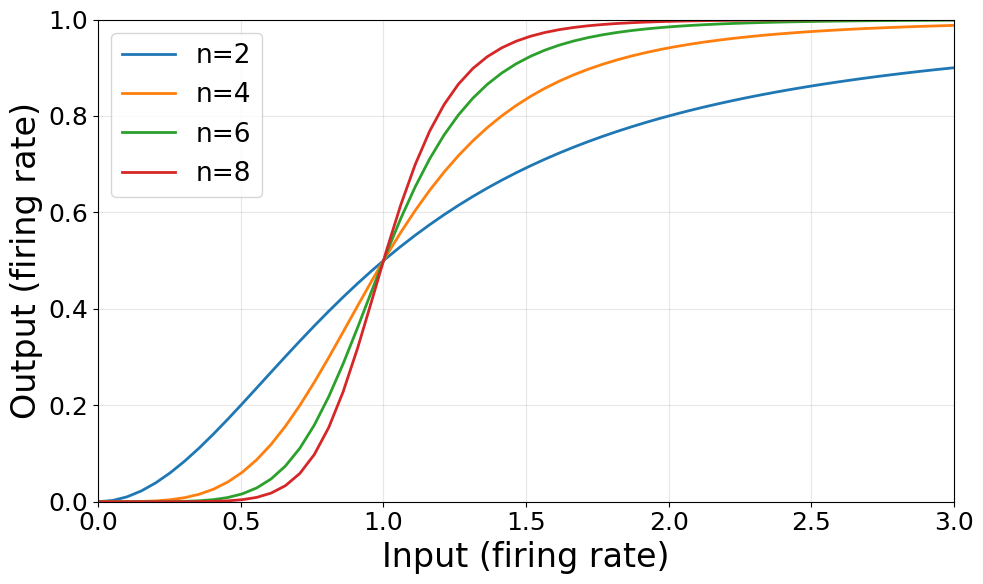

In [89]:
# Visualise the Naka-Rushton function
x_vals = jnp.linspace(0, 5, 100)
n_values = [2, 4, 6, 8]

plt.figure(figsize=(10, 6))
for n in n_values:
    y_vals = nr(x_vals, n=n)
    plt.plot(x_vals, y_vals, label=f'n={n}', linewidth=2)

plt.xlabel('Input (firing rate)', fontsize=24)
plt.ylabel('Output (firing rate)', fontsize=24)
plt.grid(True, alpha=0.3)
plt.xlim(0, 3)
plt.ylim(0, 1)
#plt.axhline(y=0.5, color='r', linestyle='--', alpha=0.5, label='Target firing rate (0.5)')
plt.tick_params(axis='both', direction='out')
plt.legend(fontsize=19)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.tight_layout()
plt.savefig(f'Figures/Naka_Rushton.eps')
plt.show()


### Simple Circuit Example

Consider a simple two-neuron circuit where:
- $x$ is the input firing rate
- $z$ is the output of the first neuron after Naka-Rushton: $z = f(x)$
- $y$ is the final output: $y = f(w \cdot z)$

where $w$ is the synaptic weights representing the strength of connections.


In [ ]:
# simple circuit demo
def simple_circuit(x, w, n=4):
    """Simple three-neuron circuit: x -> z -> y"""
    z = nr(x, n=n)
    y = nr(w * z, n=n)
    return y, z

# example
x_input = 1.0
w = 1

y_out, z_out = simple_circuit(x_input, w)

print(f"Input signal: x = {x_input:.2f}")
print(f"After first neuron: z = {z_out:.4f}")
print(f"After second neuron: y = {y_out:.4f}")


Input signal: x = 1.00
After first neuron: z = 0.5000
After second neuron: y = 0.0588


In [ ]:
# true circuit
'''
b = nr(w_osn_b * alpha * x)
r = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g)
g = nr(w_osn_g * alpha * x - w_b_g * b + w_r_g * r)

y = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g + w_r_y * r)

'''

'\nb = nr(w_osn_b * alpha * x)\nr = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g)\ng = nr(w_osn_g * alpha * x - w_b_g * b + w_r_g * r)\n\ny = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g + w_r_y * r)\n\n'

## 2. Fixed Point Iteration

In the olfactory bulb circuit, neurons have recurrent connections, creating feedback loops. To find the steady-state firing rates, we need to solve for fixed points where the system reaches equilibrium.

For the green (g) neurons, the fixed point equation is:

g = nr(w_osn_g * alpha * x - w_b_g * [nr(w_osn_b * alpha * x)] + w_r_g * [nr(w_osn_r * alpha * x - w_b_r * [nr(w_osn_b * alpha * x)] - W_g_r @ g)])


We use **Anderson Acceleration** to efficiently solve this fixed point equation.

In [185]:
# demonstrate fixed point iteration for green neurons

# set up parameters
m = 2  # number of mitral neurons
x = jnp.ones(m)  # input odour signal
w_osn_r = jnp.array([0.5, 0.5])
w_osn_b = jnp.array([0.5, 0.5])
w_osn_g = jnp.array([0.5, 0.5])
w_osn_y = jnp.array([0.5, 0.5])
w_b_r = jnp.array([0.5, 0.5])
w_b_g = jnp.array([0.5, 0.5])
w_b_y = jnp.array([0.5, 0.5])
w_r_y = jnp.array([0.5, 0.5])
w_r_g = jnp.array([0.5, 0.5])
alpha = jnp.array([1.0, 1.0])  # scaling factor
W_g_r = jnp.array([[0, 0.5], [0, 0.5]])
W_g_y = jnp.array([[0, 0.5], [0, 0.5]])

# initial guess
g0 = jnp.zeros(m)

# solve using Anderson Acceleration
aa = AndersonAcceleration(mitral_fixed_point, history_size=5, tol=1e-6, maxiter=5)
solution = aa.run(g0, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha)
g_fixed = solution.params

print(f"Fixed point solution for green neurons (g):")
print(f"g = {np.array(g_fixed)}")
print(f"\nNumber of iterations: {solution.state.iter_num}")


# verify it's a fixed point
g_verify = mitral_fixed_point(g_fixed, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha)
print(f"\nVerification (should be close to g):")
print(f"g_new = {np.array(g_verify)}")


Fixed point solution for green neurons (g):
g = [0.05417495 0.05417495]

Number of iterations: 5

Verification (should be close to g):
g_new = [0.05417495 0.05417495]


## 3. Parameter Initialisation

Given known input odour signals and target output firing rates from the mitral cells, we want to find parameter configurations (weights) that produce these outputs.

**Strategy:**
1. Sample initial parameters from parameter space
2. Use Adam optimiser to minimise the loss function
3. The loss function measures the difference between actual y and target y firing rates (0.5)
4. Constrain outputs 


In [ ]:
# set up optimisation problem
m = 2  # number of mitral neurons
n_var = 4  # r, g, b, y
n = n_var * m  # total state length
x = jnp.ones(m)  # input odour signal

# target firing rates (all neurons should fire around 0.5)
y_target = jnp.array([0.5, 0.5])  # mitral cell output
g_target = jnp.array([0.5, 0.5])  # green neurons
b_target = jnp.array([0.5, 0.5])  # blue neurons
r_target = jnp.array([0.5, 0.5])  # red neurons

# number of parameters in the model
# parameters: w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g,
#            alpha, W_g_r, W_g_y
no_params = 28  # total number of parameters

print(f"Setup:")
print(f"  - Number of mitral neurons (channels): {m}")
print(f"  - Number of parameters: {no_params}")
print(f"  - Target firing rates: {np.array(y_target)}")
print(f"  - Input signal: {np.array(x)}")


Setup:
  - Number of mitral neurons (channels): 2
  - Number of parameters: 28
  - Target firing rates: [0.5 0.5]
  - Input signal: [1. 1.]


In [ ]:
# define loss function
def loss_fn(theta):
    """Loss function: sum of squared differences from target firing rates"""
    r, g, b, y = mitral_output(theta, x, m)
    loss = (jnp.sum((r - r_target) ** 2) +
            jnp.sum((g - g_target) ** 2) +
            jnp.sum((b - b_target) ** 2) +
            jnp.sum((y - y_target) ** 2))
    return loss

In [ ]:
def adam_optimiser(loss_fn, theta_init, lr=0.01, steps=500, beta1=0.9, beta2=0.999, eps=1e-8):
    """
    Adam optimiser using optax (JAX-native optimization library)
    """

    grad_fn = jax.jit(jax.grad(loss_fn))
    loss_fn_jit = jax.jit(loss_fn)

    # pre-compile functions
    _ = grad_fn(theta_init)
    _ = loss_fn_jit(theta_init)

    optimizer = optax.adam(learning_rate=lr, b1=beta1, b2=beta2, eps=eps)
    opt_state = optimizer.init(theta_init)

    loss_history = []
    theta = theta_init

    for step in range(steps):
        grad = grad_fn(theta)
        updates, opt_state = optimizer.update(grad, opt_state, theta)
        theta = optax.apply_updates(theta, updates)

        # keep weights non-negative
        theta = jnp.clip(theta, 0.0, None)

        # keep alpha between 0 and 1
        alpha_start_idx = 9 * m
        alpha_end_idx = 10 * m
        theta = theta.at[alpha_start_idx:alpha_end_idx].set(
            jnp.clip(theta[alpha_start_idx:alpha_end_idx], 0.0, 1.0)
        )

        # keep matrix diagonal to 0
        theta = theta.at[-1].set(0)
        theta = theta.at[-4].set(0)
        theta = theta.at[-5].set(0)
        theta = theta.at[-8].set(0)

        if step % 20 == 0 or step == steps - 1:
            loss_float = float(loss_fn_jit(theta))
            loss_history.append(loss_float)
    return theta, loss_history


In [187]:
# sample initial parameters
no_samples = 10  # number of different starting points
key = jax.random.PRNGKey(0)
theta_matrix = jax.random.uniform(key, (no_samples, no_params), minval=0.0, maxval=1.0)

#for all the matrices weights , set the diagonal to 0
for i in range(no_samples):
    theta_matrix = theta_matrix.at[i, -1].set(0)
    theta_matrix = theta_matrix.at[i, -4].set(0)
    theta_matrix = theta_matrix.at[i, -5].set(0)
    theta_matrix = theta_matrix.at[i, -8].set(0)


print(f"Sampled {no_samples} initial parameter sets")
print(f"Initial parameter matrix shape: {theta_matrix.shape}")

Sampled 10 initial parameter sets
Initial parameter matrix shape: (10, 28)


In [ ]:
# run optimisation for each sample
theta_opt = jnp.zeros((no_samples, no_params))
r_opt = jnp.zeros((no_samples, m))
g_opt = jnp.zeros((no_samples, m))
b_opt = jnp.zeros((no_samples, m))
y_opt = jnp.zeros((no_samples, m))
all_loss_histories = []

print("Running Adam optimizer...\n")

for i in range(no_samples):
    print(f"Sample {i+1}/{no_samples}:")
    theta_init = theta_matrix[i, :]
    initial_loss = loss_fn(theta_init)
    print(f"  Initial loss: {initial_loss:.6f}")

    theta_optimised, loss_history = adam_optimiser(
        loss_fn, theta_init, lr=0.01, steps=500
    )
    all_loss_histories.append(loss_history)

    theta_opt = theta_opt.at[i, :].set(theta_optimised)
    r, g, b, y = mitral_output(theta_optimised, x, m)

    r_opt = r_opt.at[i, :].set(r)
    g_opt = g_opt.at[i, :].set(g)
    b_opt = b_opt.at[i, :].set(b)
    y_opt = y_opt.at[i, :].set(y)

    final_loss = loss_fn(theta_optimised)
    print(f"  Final loss: {final_loss:.6f}")
    print(f"  Output y: {np.array(y)}")
    print()

# save theta_opt as pickle file
# create Theta_opt directory if it doesn't exist
os.makedirs('Theta_opt', exist_ok=True)

with open(f'Theta_opt/theta_opt_{theta_opt.shape[0]}_samples_n_4_target_0.5.pkl', 'wb') as f:
    pickle.dump(theta_opt, f)


Running Adam optimizer...

Sample 1/1000:
  Initial loss: 1.863522
  Final loss: 0.000000
  Output y: [0.5 0.5]

Sample 2/1000:
  Initial loss: 1.747438
  Final loss: 0.000000
  Output y: [0.5        0.49999994]

Sample 3/1000:
  Initial loss: 1.980679
  Final loss: 0.000000
  Output y: [0.5000001  0.49999988]

Sample 4/1000:
  Initial loss: 1.701030
  Final loss: 0.000000
  Output y: [0.5 0.5]

Sample 5/1000:
  Initial loss: 1.901523
  Final loss: 0.000000
  Output y: [0.49999994 0.5       ]

Sample 6/1000:
  Initial loss: 1.866467
  Final loss: 0.000000
  Output y: [0.49999988 0.5       ]

Sample 7/1000:
  Initial loss: 1.936196
  Final loss: 0.000000
  Output y: [0.5 0.5]

Sample 8/1000:
  Initial loss: 1.975497
  Final loss: 0.000000
  Output y: [0.5 0.5]

Sample 9/1000:
  Initial loss: 1.981849
  Final loss: 0.000000
  Output y: [0.5        0.49999988]

Sample 10/1000:
  Initial loss: 1.991039
  Final loss: 0.000000
  Output y: [0.5        0.49999988]

Sample 11/1000:
  Initial lo

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


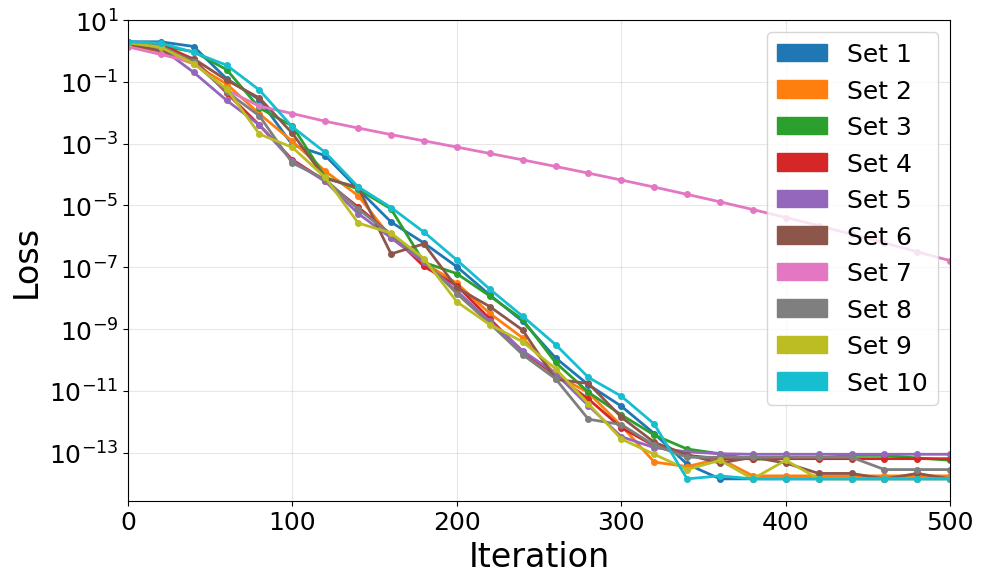

Optimization results:
Target output: [0.5 0.5]

Optimized outputs:
  Sample 1: y = [0.5 0.5]
  Sample 2: y = [0.5 0.5]
  Sample 3: y = [0.5000001 0.5      ]
  Sample 4: y = [0.5        0.49999994]
  Sample 5: y = [0.5000001 0.5000001]
  Sample 6: y = [0.5 0.5]
  Sample 7: y = [0.4999808  0.49999988]
  Sample 8: y = [0.5000001 0.5      ]
  Sample 9: y = [0.5       0.5000001]
  Sample 10: y = [0.5 0.5]


In [ ]:
plt.figure(figsize=(10, 6))

# keep track of the line objects so we can get their colors
lines = []

for i, loss_hist in enumerate(all_loss_histories):
    steps = np.arange(0, len(loss_hist)) * 20
    line, = plt.plot(steps, loss_hist, 'o-', linewidth=2, markersize=4)
    lines.append(line)  # store line object

plt.xlabel('Iteration', fontsize=24)
plt.ylabel('Loss', fontsize=24)
plt.yscale('log')
plt.xlim(0, 500)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.grid(True, alpha=0.3)

# create legend using the colors of the actual plotted lines
legend_handles = [Patch(color=line.get_color(), label=f'Set {i+1}')
                  for i, line in enumerate(lines)]
plt.legend(handles=legend_handles,loc='upper right',  fontsize=18)

plt.tight_layout()
plt.savefig('Figures/loss_convergence.eps')
plt.show()

print("Optimization results:")
print(f"Target output: {np.array(y_target)}")
print(f"\nOptimized outputs:")
for i in range(y_opt.shape[0]):
    print(f"  Sample {i+1}: y = {np.array(y_opt[i])}")

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


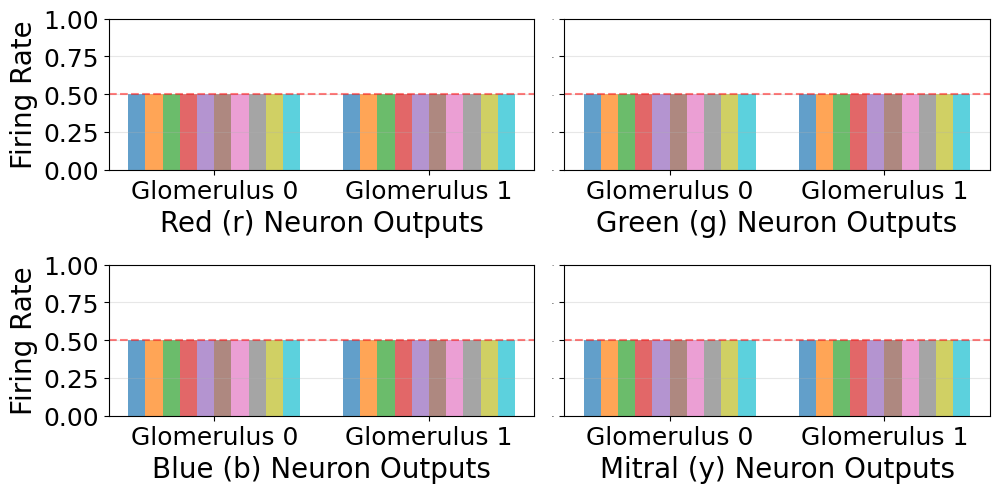


Summary of neuron outputs:

Red (r):
  Mean: 0.5000
  Std:  0.0000
  Min:  0.5000
  Max:  0.5000
  Target distance: 0.0000

Green (g):
  Mean: 0.5000
  Std:  0.0000
  Min:  0.4998
  Max:  0.5000
  Target distance: 0.0000

Blue (b):
  Mean: 0.5000
  Std:  0.0001
  Min:  0.5000
  Max:  0.5004
  Target distance: 0.0000

Mitral (y):
  Mean: 0.5000
  Std:  0.0000
  Min:  0.5000
  Max:  0.5000
  Target distance: 0.0000


In [ ]:

###############################
# plot the output values of r, g, b, y for all samples
plt.figure(figsize=(10, 6))

# create subplots for each neuron type
neuron_types = ['Red (r)', 'Green (g)', 'Blue (b)', 'Mitral (y)']
outputs = [r_opt, g_opt, b_opt, y_opt]

for idx, (neuron_type, output) in enumerate(zip(neuron_types, outputs)):
    plt.subplot(2, 2, idx + 1)

    x_pos = np.arange(m)
    width = 0.8 / y_opt.shape[0]

    # plot bars for each sample with multicolored coding
    for i in range(y_opt.shape[0]):
        plt.bar(x_pos + i*width, np.array(output[i]), width,
                label=f'Sample {i+1}' if idx == 0 else '', alpha=0.7)

    # add target line at 0.5
    plt.axhline(y=0.5, color='red', linestyle='--', linewidth=1.5,
                alpha=0.5, label='Target (0.5)')

    # Y-axis
    # only for the left plots
    if idx == 0 or idx == 2 :
        plt.ylabel('Firing Rate', fontsize=20)
        plt.yticks(fontsize=18)
    else:
        plt.yticks(fontsize=0)

    # subplot x-axis ticks
    plt.xticks(x_pos + 4.5*width, [f'Glomerulus {j}' for j in range(m)], fontsize=14)
    plt.xlabel(f'{neuron_type} Neuron Outputs', fontsize=20)
    plt.xticks(fontsize=18)
    plt.ylim([0, 1.0])
    plt.grid(True, alpha=0.3, axis='y')

# legend only once
# central x-axis label for the whole figure
plt.tight_layout(rect=[0, 0.1, 1, 0.95])
plt.savefig('Figures/neuron_outputs_rgby.eps')
plt.show()

# print summary statistics
print("\nSummary of neuron outputs:")
print("=" * 60)
for neuron_type, output in zip(neuron_types, outputs):
    output_array = np.array(output)
    print(f"\n{neuron_type}:")
    print(f"  Mean: {output_array.mean():.4f}")
    print(f"  Std:  {output_array.std():.4f}")
    print(f"  Min:  {output_array.min():.4f}")
    print(f"  Max:  {output_array.max():.4f}")
    print(f"  Target distance: {np.abs(output_array - 0.5).mean():.4f}")


## Stability

To analyse the stability of the network around a candidate fixed point, we consider the state vector $s(t)$ representing the outputs of neurons across all channels. Let $s^\ast$ denote the steady-state solution for a given set of parameters $\theta$, i.e. the fixed point where 
$ F(s^\ast, \theta, x, m) = s^\ast$

We introduce a small perturbation $e(t)$ around the fixed point:
$s(t) = s^\ast + e(t)$

Linearising around $s^\ast$ gives
$\tau \frac{d e}{dt} = - e + J \, e, \quad \text{where} \quad
J = \left. \frac{\partial F}{\partial s} \right|_{s = s^\ast}$.

Rewriting this, we obtain a standard continuous-time linear system:
$ \frac{d e}{dt} = \frac{1}{\tau} (J - I) \, e = A \, e$.
The fixed point is locally asymptotically stable if all eigenvalues of $A$ have negative real parts, ensuring that the perturbation $e(t)$ decays over time.


### Implementation

We implement stability analysis by:
1. Defining the state vector $s$ as the concatenated outputs $[r, g, y]$ (blue neurons $b$ are computed directly from input and do not contribute to dynamics)
2. Computing the Jacobian matrix $J = \frac{\partial F}{\partial s}$ at the fixed point using automatic differentiation
3. Computing the stability matrix $A = \frac{1}{\tau}(J - I)$ where $\tau$ is the time constant
4. Checking if all eigenvalues of $A$ have negative real parts


In [ ]:
# define the dynamics function F(s, theta, x, m)
# state vector s = [r,g,y]
def F(s, theta, x, m):
    """
    Dynamics function that computes the next state from current state s.
    """
    # Unpack state vector
    r = s[:m]
    g = s[m:2*m]
    y = s[2*m:3*m]

    # unpack parameters
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)

    # compute b (doesn't depend on state, only on input)
    b = nr(w_osn_b * alpha * x)

    # compute new r from current g
    r_new = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g)

    # compute new g from current r
    g_new = nr(w_osn_g * alpha * x - w_b_g * b + w_r_g * r)

    # compute new y from g_new and r_new
    y_new = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g_new + w_r_y * r_new)

    # return concatenated state vector
    s_prime = jnp.concatenate([r_new, g_new, y_new])
    return s_prime


In [ ]:
# compute Jacobian matrix J = dF/ds at the fixed point s_star
def compute_jacobian(F, s_star, theta, x, m):
    # create a function that only depends on s (for JAX differentiation)
    def F_s(s):
        return F(s, theta, x, m)

    # jax.jacobian computes the Jacobian matrix: J[i,j] = dF_i/ds_j
    J = jax.jacobian(F_s)(s_star)
    return J


In [ ]:
# compute matrix A and check stability
def compute_stability(F, s_star, theta, x, m, tau=1.0):
    n = s_star.shape[0]
    I = jnp.eye(n)
    J = compute_jacobian(F, s_star, theta, x, m)
    A = (1 / tau) * (J - I)

    eigenvalues = jnp.linalg.eigvals(A)
    eigenvalues_np = np.array(eigenvalues)

    # check stability - all eigenvalues must have negative real parts
    real_parts = np.real(eigenvalues_np)
    is_stable = np.all(real_parts < 0.0)

    return {
        'J': J,
        'A': A,
        'eigenvalues': eigenvalues_np,
        'is_stable': is_stable,
        'real_parts': real_parts
    }


In [ ]:
# load theta_opt from pickle file

with open('Theta_opt/theta_opt_10_samples_n_4_target_0.5.pkl', 'rb') as f:
    theta_opt = pickle.load(f)

print(f"Loaded theta_opt with shape: {theta_opt.shape}")
print(f"Number of samples: {theta_opt.shape[0]}")
print(f"Number of parameters per sample: {theta_opt.shape[1]}")


Loaded theta_opt with shape: (10, 28)
Number of samples: 10
Number of parameters per sample: 28


In [ ]:
# run stability analysis on optimised parameters
print("=" * 70)
print("STABILITY ANALYSIS")
print("=" * 70)
actual_no_samples = theta_opt.shape[0]
print(f"\nAnalysing stability for {actual_no_samples} optimised parameter sets...\n")

tau = 1
stability_results = []
remove_row = []
for i in range(actual_no_samples):
    print(f"\n--- Sample {i+1}/{actual_no_samples} ---")

    # get optimised parameters and fixed point outputs
    theta_star = theta_opt[i, :]
    r_star, g_star, b_star, y_star = mitral_output(theta_star, x, m)

    # construct state vector s* = [r, g, y]
    s_star = jnp.concatenate([r_star, g_star, y_star])

    # verify it's a fixed point (should be close to s*)
    s_prime = F(s_star, theta_star, x, m)
    s_error = jnp.linalg.norm(s_prime - s_star)
    print(f"\nFixed point error ||F(s*) - s*|| = {float(s_error):.2e}")

    # compute stability
    result = compute_stability(F, s_star, theta_star, x, m, tau=tau)
    stability_results.append(result)

    # print results
    print(f"\nStability Analysis:")
    print(f"  Is stable: {result['is_stable']}")

    if result['is_stable'] == False:
        remove_row.append(i)

print(remove_row)


STABILITY ANALYSIS

Analyzing stability for 1000 optimized parameter sets...


--- Sample 1/1000 ---

Fixed point error ||F(s*) - s*|| = 0.00e+00

Stability Analysis:
  Is stable: True

--- Sample 2/1000 ---

Fixed point error ||F(s*) - s*|| = 0.00e+00

Stability Analysis:
  Is stable: True

--- Sample 3/1000 ---

Fixed point error ||F(s*) - s*|| = 1.33e-07

Stability Analysis:
  Is stable: True

--- Sample 4/1000 ---

Fixed point error ||F(s*) - s*|| = 0.00e+00

Stability Analysis:
  Is stable: True

--- Sample 5/1000 ---

Fixed point error ||F(s*) - s*|| = 0.00e+00

Stability Analysis:
  Is stable: True

--- Sample 6/1000 ---

Fixed point error ||F(s*) - s*|| = 0.00e+00

Stability Analysis:
  Is stable: True

--- Sample 7/1000 ---

Fixed point error ||F(s*) - s*|| = 0.00e+00

Stability Analysis:
  Is stable: True

--- Sample 8/1000 ---

Fixed point error ||F(s*) - s*|| = 0.00e+00

Stability Analysis:
  Is stable: True

--- Sample 9/1000 ---

Fixed point error ||F(s*) - s*|| = 0.00e+0

In [163]:
result = compute_stability(F, s_star, theta_star, x, m, tau=tau)
print(result['J'])

[[ 0.          0.          0.         -0.334448    0.          0.        ]
 [ 0.          0.          1.3311242   0.          0.          0.        ]
 [ 0.8734506   0.          0.          0.          0.          0.        ]
 [ 0.          0.80031574  0.          0.          0.          0.        ]
 [ 0.         -0.4489576   0.         -0.1607985   0.          0.        ]
 [-0.01278867  0.          1.6197325   0.          0.          0.        ]]


In [ ]:
# remove unstable theta
theta_opt = np.array(theta_opt)
y_opt = np.array(y_opt)

max_index = theta_opt.shape[0] - 1
valid_remove_row = [i for i in remove_row if 0 <= i <= max_index]

for i in sorted(valid_remove_row, reverse=True):
    theta_opt = np.delete(theta_opt, i, axis=0)
    y_opt = np.delete(y_opt, i, axis=0)

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


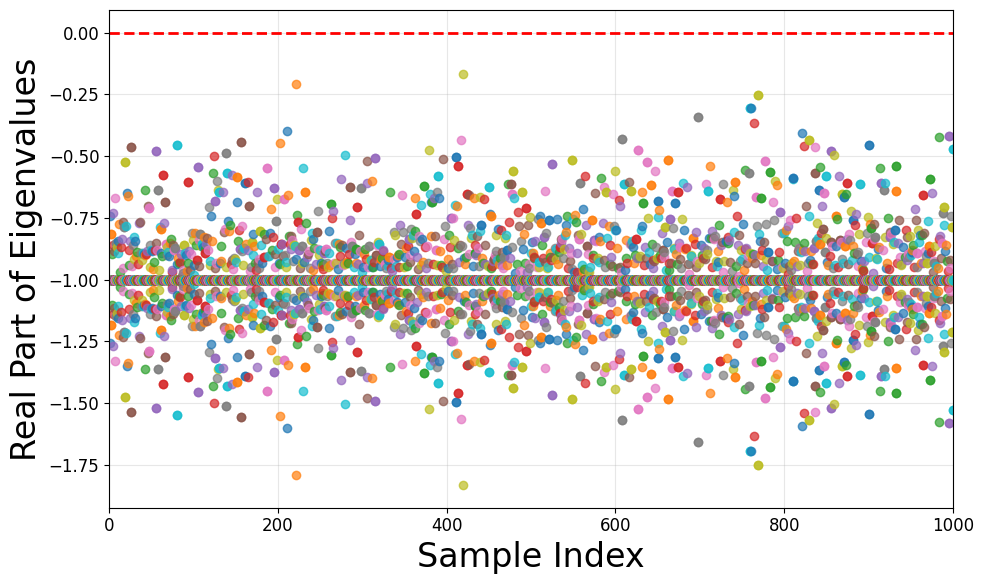


STABILITY SUMMARY

Stable samples: 1000/1000 (100.0%)


In [ ]:
# visualise stability results
fig, ax1 = plt.subplots(1, 1, figsize=(10, 6))

# use actual number of samples
actual_no_samples = len(stability_results)
for i in range(actual_no_samples):
    real_parts = stability_results[i]['real_parts']
    ax1.plot([i+1] * len(real_parts), real_parts, 'o', alpha=0.7, label=f'Sample {i+1}' if i < 5 else '')
ax1.axhline(y=0, color='r', linestyle='--', linewidth=2, label='Stability threshold')
ax1.set_xlabel('Sample Index', fontsize=24)
ax1.set_ylabel('Real Part of Eigenvalues', fontsize=24)
actual_no_samples = len(stability_results)
ax1.set_xlim(0, actual_no_samples)
ax1.grid(True, alpha=0.3)

stable_count = sum(1 for r in stability_results if r['is_stable'])
unstable_count = actual_no_samples - stable_count

plt.tight_layout()
plt.tick_params(axis='both', direction='out')
plt.savefig('Figures/stability.eps')
plt.show()

# print summary
print("\n" + "=" * 70)
print("STABILITY SUMMARY")
print("=" * 70)
print(f"\nStable samples: {stable_count}/{actual_no_samples} ({100*stable_count/actual_no_samples:.1f}%)")


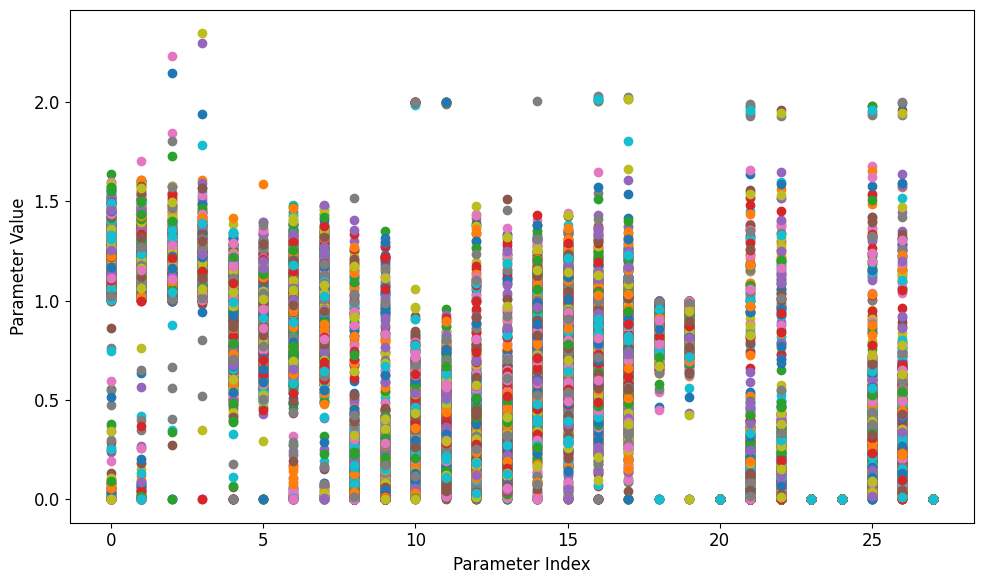

In [ ]:
# raw values
for i in range(theta_opt.shape[0]):
    plt.plot(theta_opt[i, :], marker='o', linestyle=' ')
plt.xlabel('Parameter Index', fontsize=12)
plt.ylabel('Parameter Value', fontsize=12)
#plt.xlim(0,30)
plt.tight_layout()
plt.show()


## 4. Parameter Changes Preserving Output ($\Delta \theta$)

Given a set of biologically realistic parameters $\theta$, we seek to understand how these parameters could change such that the output of the system remains unchanged. This directly addresses the initial problem: during sensory deprivation, structural changes occur (e.g., axonal shrinkage), yet functional output is preserved, suggesting compensatory parameter changes elsewhere in the circuit.

To find parameter changes $\Delta \theta$ that preserve output, we require $y(\theta + \Delta \theta) = y(\theta)$. Taking a Taylor expansion:

$ y(\theta + \Delta \theta) \approx y(\theta) + g^T \Delta \theta + \frac{1}{2} \Delta \theta^T H \, \Delta \theta + \mathcal{O}(\|\Delta \theta\|^3)$

where $g = \nabla_\theta y(\theta)$ is the gradient and $H = \nabla_\theta^2 y(\theta)$ is the Hessian matrix. For the output to remain unchanged, we require:

$y(\theta + \Delta \theta) - y(\theta) = g^T \Delta \theta + \frac{1}{2} \Delta \theta^T H \, \Delta \theta \approx 0$

The eigenvectors corresponding to near-zero eigenvalues of the Hessian define directions in parameter space where changes preserve output. By analyzing these eigenvectors, we can identify compensatory mechanisms, i.e. when certain parameters increase, others must increase/decrease to maintain constant output.


In [ ]:
m = 2  # number of mitral neurons
x = jnp.ones(m)  # input odour signal

# use one of the optimised parameter sets
theta_star = theta_opt[0, :]

# define function that returns output y
@jax.jit
def y_output_sum(theta):
    """Compute output y as a function of parameters"""
    r, g, b, y = mitral_output(theta, x, m)
    return jnp.sum(y)  # sum over all y neurons

print("Computing gradient and Hessian of output y...")
grad = jax.jit(jax.grad(y_output_sum))
hessian = jax.jit(jax.jacrev(grad))

g = grad(theta_star)
H = hessian(theta_star)
H = jnp.squeeze(H)  # remove any extra dimensions

# SVD
# s=eigenvalues
# u=eigenvectors
# u, s, vt = jnp.linalg.svd(H)

#eigen values of H
eigenvalues_H, eigenvectors_H = jnp.linalg.eigh(H)
eigenvalues_H = np.array(eigenvalues_H)
eigenvectors_H = np.array(eigenvectors_H)

# count near-zero eigenvalues (threshold: 1e-6)
near_zero_threshold = 1e-6
n_near_zero = np.sum(np.abs(eigenvalues_H) < near_zero_threshold)
print(f"\nNumber of near-zero eigenvalues (|λ| < {near_zero_threshold}): {n_near_zero}")

Computing gradient and Hessian of output y...

Number of near-zero eigenvalues (|λ| < 1e-06): 11


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


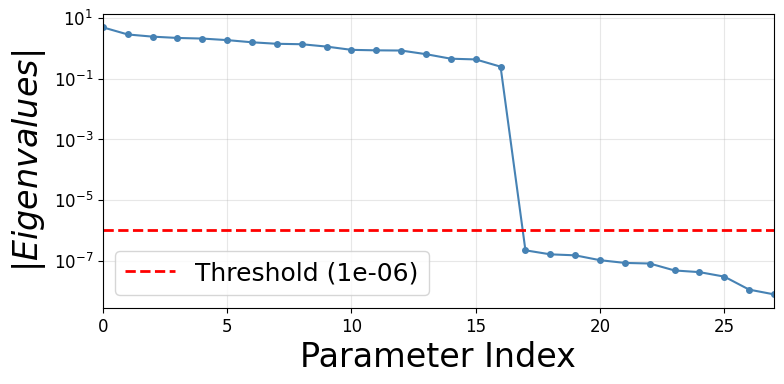

In [ ]:
# sort by absolute value
idx = np.argsort(np.abs(eigenvalues_H))[::-1]
eigenvalues_H_sorted = eigenvalues_H[idx]
eigenvectors_H_sorted = eigenvectors_H[:, idx]

# visualise Hessian eigenvalue spectrum
plt.figure(figsize=(8, 4))
plt.semilogy(np.abs(eigenvalues_H_sorted), 'o-', ms=4, lw=1.5, color='steelblue')
plt.axhline(near_zero_threshold, color='r', ls='--', lw=2,
            label=f'Threshold ({near_zero_threshold})')

plt.xlabel('Parameter Index', fontsize=24)
plt.ylabel('$|Eigenvalues|$', fontsize=24)
plt.xlim(0, 27)
plt.tick_params(axis='both', direction='out')
plt.legend(fontsize=18)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('Figures/hessian_eigenvalue_spectrum.eps', format='eps')
plt.show()


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


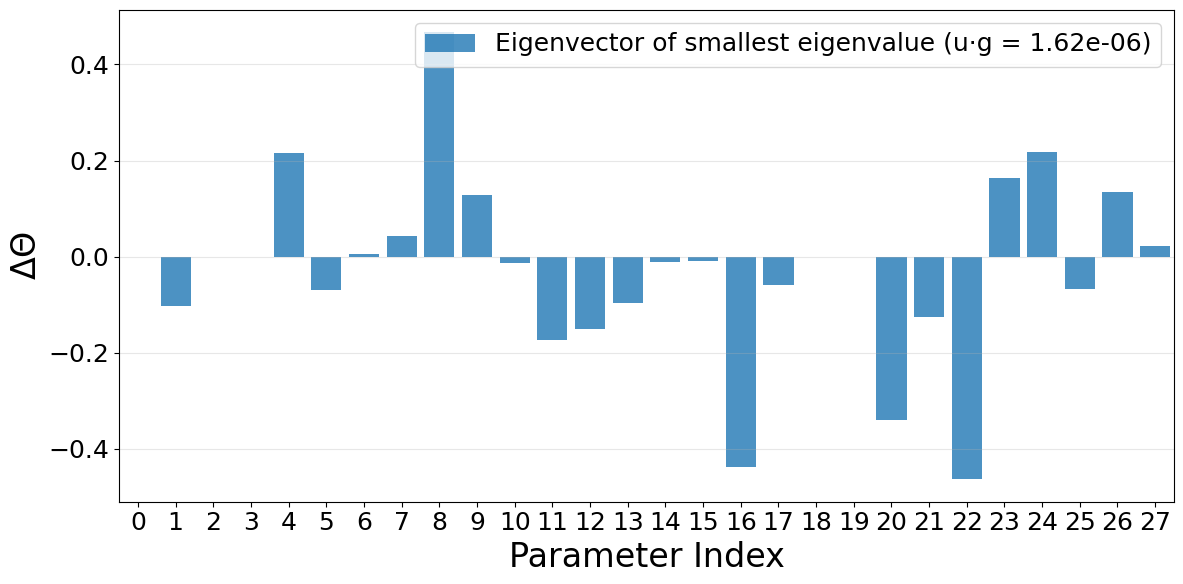

In [ ]:
# take the bottom eigen vectors and plot value vs index
plt.figure(figsize=(12, 6))
x = np.arange(28)  # parameter indices
width = 0.8  # width of bars

# compute dot products with gradient for the last eigenvector
dot_products = eigenvectors_H_sorted[:, -1:].T @ g

# plot the last eigenvector as bars centered at each x tick
for i, idx in enumerate(range(-1, 0)):
    label = f'Eigenvector of smallest eigenvalue (u·g = {dot_products[i]:.2e})'
    plt.bar(x, eigenvectors_H_sorted[:, idx], width,
            label=label, alpha=0.8)

plt.xlabel("Parameter Index", fontsize=24)
plt.ylabel("$\Delta\Theta$", fontsize=24)
plt.xlim(-0.5, 27.5)
plt.xticks(x, x, fontsize=18)  # Center ticks at x positions
plt.yticks(fontsize=18)
plt.grid(True, alpha=0.3, axis='y')
plt.legend(fontsize=18)
plt.tight_layout()
plt.tick_params(axis='both', direction='out')
plt.savefig('Figures/eigenvectors_bottom.eps')
plt.show()

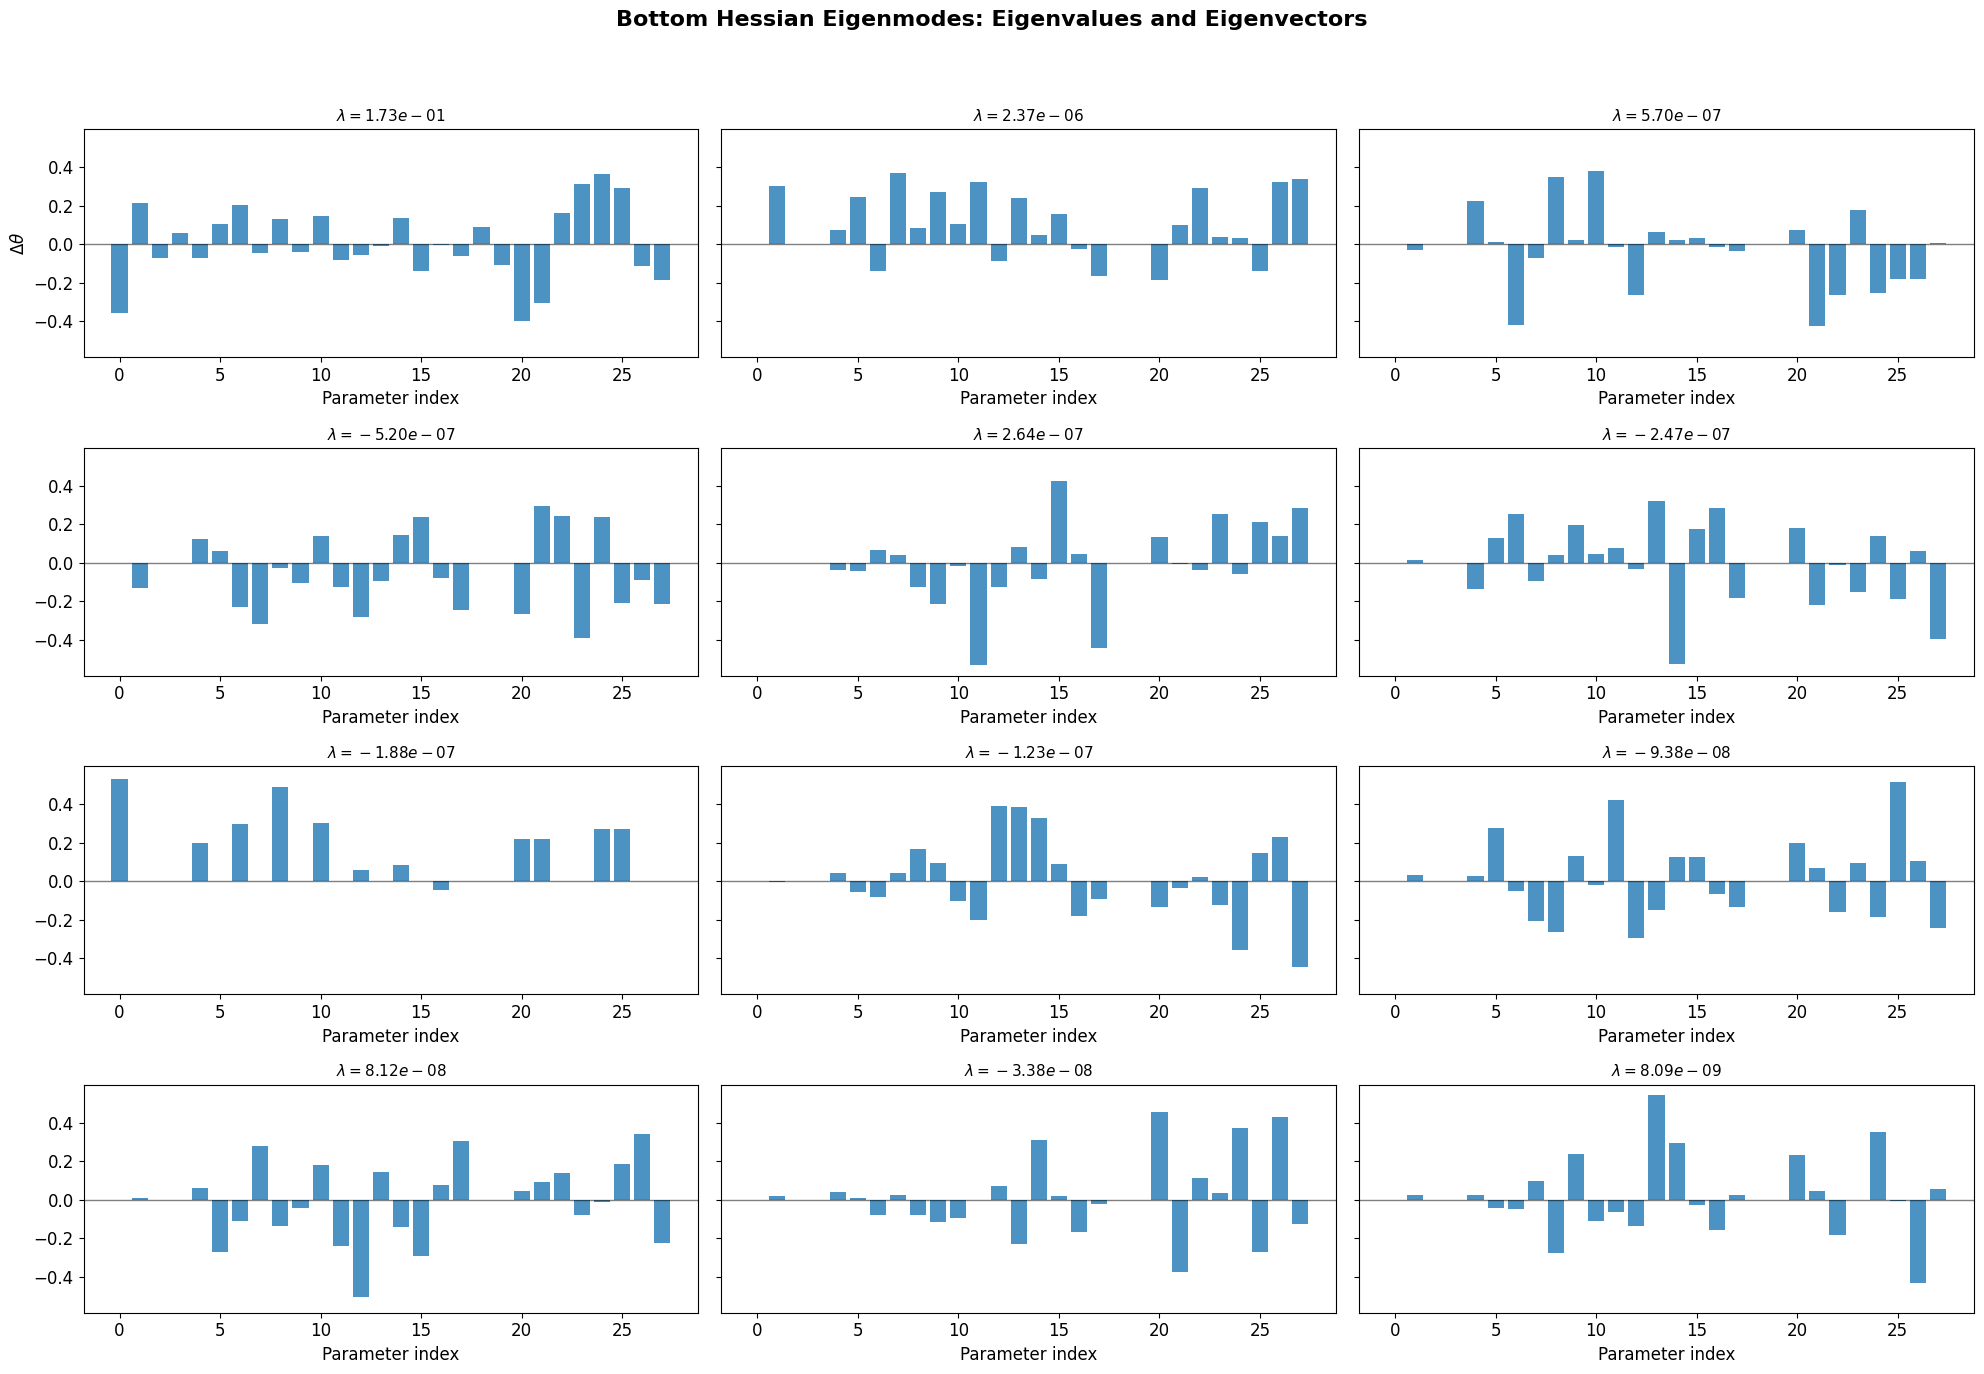

In [ ]:
# select the last eigenvalues
no_e_values = 12
indices = range(-no_e_values, 0)

fig, axes = plt.subplots(4, 3, figsize=(20, 14), sharey=True)
axes = axes.flatten()

for ax, idx in zip(axes, indices):
    eigenvector = eigenvectors_H_sorted[:, idx]
    eigenvalue = eigenvalues_H_sorted[idx]

    ax.bar(np.arange(len(eigenvector)),eigenvector,width=0.8,alpha=0.8)

    ax.axhline(0, color='k', linewidth=1, alpha=0.5)
    ax.set_title(rf'$\lambda = {eigenvalue:.2e}$',fontsize=11)
    ax.set_xlabel('Parameter index')

axes[0].set_ylabel(r'$\Delta \theta$', fontsize=12)

plt.suptitle(
    'Bottom Hessian Eigenmodes: Eigenvalues and Eigenvectors',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


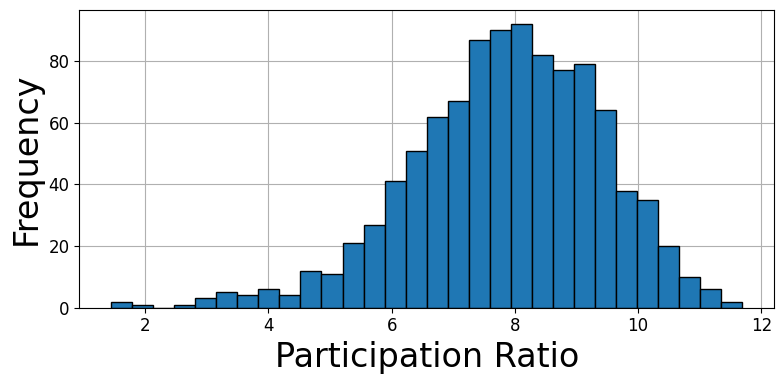

In [ ]:
## participation ratio
## plot histogram of participation ratio

participation_ratios = []
for i in range(theta_opt.shape[0]):
    H = hessian(theta_opt[i, :])
    H = jnp.squeeze(H)
    eigenvalues_H = jnp.linalg.eigh(H)[0]
    ppr = (jnp.sum(jnp.abs(eigenvalues_H)) ** 2) / jnp.sum(eigenvalues_H ** 2)
    participation_ratios.append(ppr)

participation_ratios = np.array(participation_ratios)

plt.figure(figsize=(8, 4))
plt.grid(True, zorder=0)
plt.hist(participation_ratios, bins=30, edgecolor='black', zorder=2)
plt.xlabel('Participation Ratio', fontsize=24)
plt.ylabel('Frequency', fontsize=24)
plt.tight_layout()
plt.savefig('Figures/participation_ratio.eps')
plt.show()